# 06.04 | Cross-domain synthesis of HRV associations

**Study:** Heart rate variability in older adults from southern Chile  
**Scope:** A synthesis of completed **one-factor-at-a-time** analyses from notebooks 06.01, 06.02 and 06.03.

This final notebook for phase 06 brings together the existing descriptive profiles and association estimates for seven cardiac measurements:

- **Primary HRV:** SDNN, RMSSD, HF, LF and VLF.
- **Complementary cardiac measurements:** Mean RR and Mean HR.

**Scientific questions:** (1) What direction and magnitude do the observed associations have across demographic, anthropometric and blood-pressure domains? (2) How precise are the estimates? (3) Do different HRV measurements present similar or distinct descriptive patterns?

**Strict analytical boundary:** This notebook **does not reload or modify `dataset_final.csv`**, rerun association tests, bootstrap confidence intervals, recalculate multiplicity corrections, introduce adjusted models, or construct two-factor subgroups. All effects, confidence intervals and p-values are **copied from existing output tables**. No statistical patterns are assumed in advance; every result remains represented, whether significant or not. All analyses are observational and unadjusted.

**Output:** CSV synthesis tables, high-resolution Seaborn/Matplotlib multipanel figures, a figure manifest, a methods README and a complete Markdown results report. Running the notebook creates these artifacts in its own output directory.

## 0. Configuration and presentation

Run this notebook from the project directory or any descendant, after executing 06.01–06.03. Set `ANALYSIS_ROOT_OVERRIDE` if their output folders are located elsewhere. The notebook reads **only previously generated CSVs**.

In [1]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ANALYSIS_ROOT_OVERRIDE = None  # e.g. "/absolute/project/eda_results/hrv_associations"
OUTPUT_ROOT_OVERRIDE = None    # default: <analysis_root>/06_04_association_synthesis
SHOW_FIGURES = True
PLOT_DPI = 230

PRIMARY = {
    "t2m_pre_sdnn": "SDNN", "t2m_pre_rmssd": "RMSSD", "t2m_pre_hf": "HF",
    "t2m_pre_lf": "LF", "t2m_pre_vlf": "VLF",
}
COMPLEMENTARY = {"t2m_pre_mean_rr": "Mean RR", "t2m_pre_mean_hr": "Mean HR"}
MEASURES = {**PRIMARY, **COMPLEMENTARY}
OUTCOME_ORDER = list(MEASURES)

DOMAIN_ORDER = ["Demographic", "Anthropometric", "Blood pressure"]
DOMAIN_FILES = {
    "Demographic": "06_01_demographic_associations",
    "Anthropometric": "06_02_anthropometric_associations",
    "Blood pressure": "06_03_blood_pressure_associations",
}
CONTINUOUS_META = {
    "age": ("Age", "Demographic"),
    "weight_kg": ("Weight", "Anthropometric"),
    "height_cm": ("Height", "Anthropometric"),
    "imc": ("BMI", "Anthropometric"),
    "bp_systolic": ("SBP", "Blood pressure"),
    "bp_diastolic": ("DBP", "Blood pressure"),
    "bp_pam": ("MAP", "Blood pressure"),
    "bp_pp": ("Pulse pressure", "Blood pressure"),
}
BINARY_META = {
    "sex_category": ("Sex · Female vs Male", "Demographic"),
    "sbp_category": ("SBP · ≥140 vs <140 mmHg", "Blood pressure"),
    "dbp_category": ("DBP · ≥90 vs <90 mmHg", "Blood pressure"),
}
MULTIGROUP_META = {
    "age_group": ("Age groups", "Demographic"),
    "bmi_category": ("BMI categories", "Anthropometric"),
}
NAVY, MUTED, TEAL, CORAL, PURPLE = "#19394C", "#627887", "#247E90", "#C76D52", "#7868A3"
DOMAIN_COLORS = {"Demographic": "#247E90", "Anthropometric": "#B18450", "Blood pressure": "#7868A3"}

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.02)
plt.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#DCE5EB", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#E7EDF1", "grid.alpha": 0.75,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "semibold", "figure.constrained_layout.use": False,
})
print("Python:", platform.python_version(), "| pandas:", pd.__version__, "| seaborn:", sns.__version__)

Python: 3.14.10 | pandas: 3.1.1 | seaborn: 0.13.2


## 1. Load published tables from the preceding notebooks

Inputs are the **CSV outputs**, not the original cohort. The previous notebooks retain full ownership of the statistical estimates, their uncertainty and their original within-domain BH-FDR families. Paths below match their actual export names.

In [2]:
def locate_analysis_root():
    if ANALYSIS_ROOT_OVERRIDE is not None:
        return Path(ANALYSIS_ROOT_OVERRIDE).expanduser().resolve()
    current = Path.cwd().resolve()
    for folder in (current, *current.parents):
        candidate = folder / "eda_results" / "hrv_associations"
        if candidate.is_dir():
            return candidate
        if folder.name == "hrv_associations":
            return folder
    raise FileNotFoundError("Could not find eda_results/hrv_associations; set ANALYSIS_ROOT_OVERRIDE.")

analysis_root = locate_analysis_root()
output_root = (Path(OUTPUT_ROOT_OVERRIDE).expanduser().resolve()
               if OUTPUT_ROOT_OVERRIDE else analysis_root / "06_04_association_synthesis")
tables_dir = output_root / "tables"
fig_dir = output_root / "figures" / "multipanels"
tables_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)


def load_stage_table(domain, filename, optional=False):
    path = analysis_root / DOMAIN_FILES[domain] / "tables" / filename
    if optional and not path.is_file():
        return None
    if not path.is_file():
        raise FileNotFoundError(f"Required prior-stage table is missing: {path}")
    return pd.read_csv(path)


source_tables = {
    "demo_cont": load_stage_table("Demographic", "age_continuous_spearman.csv"),
    "anthro_cont": load_stage_table("Anthropometric", "anthropometric_continuous_spearman.csv"),
    "bp_cont": load_stage_table("Blood pressure", "blood_pressure_continuous_spearman.csv"),
    "sex_binary": load_stage_table("Demographic", "sex_comparisons.csv"),
    "bp_binary": load_stage_table("Blood pressure", "blood_pressure_category_mann_whitney.csv"),
    "age_omnibus": load_stage_table("Demographic", "age_group_kruskal_wallis.csv"),
    "bmi_omnibus": load_stage_table("Anthropometric", "bmi_category_kruskal_wallis.csv"),
    "demo_profiles": load_stage_table("Demographic", "demographic_hrv_descriptive_profiles.csv"),
    "bmi_profiles": load_stage_table("Anthropometric", "bmi_category_hrv_descriptive_profiles.csv"),
    "bp_profiles": load_stage_table("Blood pressure", "blood_pressure_category_hrv_descriptive_profiles.csv"),
    "age_pairs": load_stage_table("Demographic", "age_group_pairwise_exploratory.csv", optional=True),
    "bmi_pairs": load_stage_table("Anthropometric", "bmi_category_vs_normal_exploratory.csv", optional=True),
}
print("Previously generated tables loaded from:", analysis_root)
print("Optional exploratory contrast tables available:",
      {name: source_tables[name] is not None for name in ["age_pairs", "bmi_pairs"]})
print("New synthesis outputs:", output_root)

Previously generated tables loaded from: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations
Optional exploratory contrast tables available: {'age_pairs': True, 'bmi_pairs': True}
New synthesis outputs: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/hrv_associations/06_04_association_synthesis


## 2. Integrate continuous associations

Bring together the **eight single-factor Spearman analyses** (age, weight, height, BMI, SBP, DBP, MAP and pulse pressure). Report the original rho, 95% CI, raw p-value and preexisting within-domain adjusted p-value for each of the seven outcomes. No recalculation is performed.

In [3]:
continuous = pd.concat(
    [source_tables["demo_cont"], source_tables["anthro_cont"], source_tables["bp_cont"]],
    ignore_index=True, sort=False,
)
continuous["domain"] = continuous["factor"].map(lambda v: CONTINUOUS_META[v][1])
continuous["factor_label"] = continuous["factor"].map(lambda v: CONTINUOUS_META[v][0])
continuous["outcome_class"] = np.where(continuous["outcome"].isin(PRIMARY), "Primary HRV", "Complementary cardiac")
continuous["source_notebook"] = continuous["domain"].map(DOMAIN_FILES)
continuous["n"] = continuous["n"].astype(int)
continuous = continuous[[
    "domain", "source_notebook", "factor", "factor_label", "outcome", "outcome_label",
    "outcome_class", "n", "spearman_rho", "rho_ci_low", "rho_ci_high",
    "p_raw", "p_fdr_bh", "family",
]].sort_values(["outcome", "factor"], key=lambda s: s.map({
    **{x: i for i, x in enumerate(OUTCOME_ORDER)}, **{x: i for i, x in enumerate(CONTINUOUS_META)}
}).fillna(999) if s.name in ["outcome", "factor"] else s).reset_index(drop=True)


def export_table(frame, filename):
    path = tables_dir / filename
    frame.to_csv(path, index=False, float_format="%.10g")
    return path

export_table(continuous, "continuous_associations_combined.csv")
display(continuous[["domain", "factor_label", "outcome_label", "spearman_rho",
                    "rho_ci_low", "rho_ci_high", "p_fdr_bh"]].head(18).round(3))

,domain,factor_label,outcome_label,spearman_rho,rho_ci_low,rho_ci_high,p_fdr_bh
0,Demographic,Age,SDNN,0.022,-0.080,0.126,0.701
1,Anthropometric,Weight,SDNN,-0.078,-0.181,0.017,0.264
2,Anthropometric,Height,SDNN,-0.130,-0.223,-0.026,0.059
3,Anthropometric,BMI,SDNN,-0.004,-0.110,0.094,0.965
4,Blood pressure,SBP,SDNN,0.066,-0.031,0.162,0.707
5,Blood pressure,DBP,SDNN,-0.018,-0.115,0.081,0.957
6,Blood pressure,MAP,SDNN,0.013,-0.090,0.108,0.957
7,Blood pressure,Pulse pressure,SDNN,0.126,0.029,0.222,0.168
8,Demographic,Age,RMSSD,0.001,-0.093,0.101,0.984
9,Anthropometric,Weight,RMSSD,-0.099,-0.195,0.005,0.185


## 3. Integrate binary contrasts and multi-group effects separately

**Binary contrasts:** Cliff's delta retains the exact sign convention from each source table: *Female versus Male*; *SBP ≥140 versus <140 mmHg*; *DBP ≥90 versus <90 mmHg*. Each CI and median difference remains attached to its original contrast.

**Multi-group contrasts:** age-group and BMI-category Kruskal–Wallis epsilon-squared effects measure overall rank-distribution differences and **have no direction**. Epsilon-squared and Cliff's delta will never share a common effect axis.

In [4]:
sex = source_tables["sex_binary"].copy()
sex_binary = pd.DataFrame({
    "factor": sex["factor"], "outcome": sex["outcome"], "outcome_label": sex["outcome_label"],
    "comparison": "Female", "reference": "Male", "n_comparison": sex["n_female"],
    "n_reference": sex["n_male"], "median_comparison": sex["median_female"],
    "median_reference": sex["median_male"],
    "median_difference_comparison_minus_reference": sex["median_difference_female_minus_male"],
    "median_diff_ci_low": sex["median_diff_ci_low"], "median_diff_ci_high": sex["median_diff_ci_high"],
    "cliffs_delta": sex["cliffs_delta_female_vs_male"],
    "cliffs_ci_low": sex["cliffs_ci_low"], "cliffs_ci_high": sex["cliffs_ci_high"],
    "p_raw": sex["p_raw"], "p_fdr_bh": sex["p_fdr_bh"], "family": sex["family"],
})
bp = source_tables["bp_binary"].copy()
bp_binary = pd.DataFrame({
    "factor": bp["factor"], "outcome": bp["outcome"], "outcome_label": bp["outcome_label"],
    "comparison": bp["comparison"], "reference": bp["reference"],
    "n_comparison": bp["n_comparison"], "n_reference": bp["n_reference"],
    "median_comparison": bp["median_comparison"], "median_reference": bp["median_reference"],
    "median_difference_comparison_minus_reference": bp["median_difference_high_minus_low"],
    "median_diff_ci_low": bp["median_diff_ci_low"], "median_diff_ci_high": bp["median_diff_ci_high"],
    "cliffs_delta": bp["cliffs_delta_high_vs_low"],
    "cliffs_ci_low": bp["cliffs_ci_low"], "cliffs_ci_high": bp["cliffs_ci_high"],
    "p_raw": bp["p_raw"], "p_fdr_bh": bp["p_fdr_bh"], "family": bp["family"],
})
binary = pd.concat([sex_binary, bp_binary], ignore_index=True, sort=False)
binary["domain"] = binary["factor"].map(lambda v: BINARY_META[v][1])
binary["factor_label"] = binary["factor"].map(lambda v: BINARY_META[v][0])
binary["source_notebook"] = binary["domain"].map(DOMAIN_FILES)
binary["outcome_class"] = np.where(binary["outcome"].isin(PRIMARY), "Primary HRV", "Complementary cardiac")
binary = binary[[
    "domain", "source_notebook", "factor", "factor_label", "outcome", "outcome_label", "outcome_class",
    "comparison", "reference", "n_comparison", "n_reference", "median_comparison", "median_reference",
    "median_difference_comparison_minus_reference", "median_diff_ci_low", "median_diff_ci_high",
    "cliffs_delta", "cliffs_ci_low", "cliffs_ci_high", "p_raw", "p_fdr_bh", "family",
]]
export_table(binary, "binary_cliffs_delta_combined.csv")

multigroup = pd.concat([source_tables["age_omnibus"], source_tables["bmi_omnibus"]],
                       ignore_index=True, sort=False)
multigroup["domain"] = multigroup["factor"].map(lambda v: MULTIGROUP_META[v][1])
multigroup["factor_label"] = multigroup["factor"].map(lambda v: MULTIGROUP_META[v][0])
multigroup["source_notebook"] = multigroup["domain"].map(DOMAIN_FILES)
multigroup["outcome_class"] = np.where(multigroup["outcome"].isin(PRIMARY), "Primary HRV", "Complementary cardiac")
multigroup = multigroup[[
    "domain", "source_notebook", "factor", "factor_label", "outcome", "outcome_label", "outcome_class",
    "n", "k", "group_sizes", "kruskal_h", "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high",
    "p_raw", "p_fdr_bh", "family",
]]
export_table(multigroup, "multigroup_epsilon_squared_combined.csv")
display(binary[["factor_label", "outcome_label", "cliffs_delta", "cliffs_ci_low", "cliffs_ci_high"]].head(9).round(3))
display(multigroup[["factor_label", "outcome_label", "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high"]].head(8).round(3))

,factor_label,outcome_label,cliffs_delta,cliffs_ci_low,cliffs_ci_high
0,Sex · Female vs Male,SDNN,0.407,0.286,0.525
1,Sex · Female vs Male,RMSSD,0.167,0.044,0.300
2,Sex · Female vs Male,HF,0.161,0.028,0.290
3,Sex · Female vs Male,LF,0.190,0.059,0.314
4,Sex · Female vs Male,VLF,0.239,0.104,0.360
5,Sex · Female vs Male,Mean RR,0.024,-0.108,0.159
6,Sex · Female vs Male,Mean HR,-0.021,-0.149,0.110
7,SBP · ≥140 vs <140 mmHg,SDNN,0.042,-0.093,0.178
8,SBP · ≥140 vs <140 mmHg,RMSSD,0.091,-0.048,0.227


,factor_label,outcome_label,epsilon_squared,epsilon_ci_low,epsilon_ci_high
0,Age groups,SDNN,0.002,0,0.030
1,Age groups,RMSSD,0.000,0,0.020
2,Age groups,HF,0.008,0,0.041
3,Age groups,LF,0.016,0,0.058
4,Age groups,VLF,0.010,0,0.043
5,Age groups,Mean RR,0.017,0,0.055
6,Age groups,Mean HR,0.017,0,0.058
7,BMI categories,SDNN,0.008,0,0.047


## 4. Integrate categorical distribution profiles and optional exploratory contrasts

Retain source-scale descriptive statistics from every existing sex, age-group, BMI and blood-pressure category. The repeated **All** row from the three notebooks is kept only once. If exploratory contrasts were enabled in 06.01 or 06.02, include their preexisting Holm-adjusted results **without rerunning tests**.

In [5]:
profiles = []
for key, domain in [("demo_profiles", "Demographic"), ("bmi_profiles", "Anthropometric"),
                    ("bp_profiles", "Blood pressure")]:
    part = source_tables[key].copy()
    if key != "demo_profiles":
        part = part.loc[part["factor"] != "all"].copy()
    part["domain"] = domain
    part["source_notebook"] = DOMAIN_FILES[domain]
    profiles.append(part)
profiles = pd.concat(profiles, ignore_index=True, sort=False)
cols = ["domain", "source_notebook", "factor", "category", "outcome", "outcome_label"]
profiles = profiles[cols + [c for c in profiles.columns if c not in cols]]
export_table(profiles, "categorical_descriptive_profiles_combined.csv")

exploratory_parts = []
if source_tables["age_pairs"] is not None:
    a = source_tables["age_pairs"]
    exploratory_parts.append(pd.DataFrame({
        "domain": "Demographic", "factor": "age_group", "outcome": a["outcome"],
        "outcome_label": a["outcome_label"], "comparison": a["group_a"], "reference": a["group_b"],
        "n_comparison": a["n_a"], "n_reference": a["n_b"],
        "median_difference_comparison_minus_reference": a["median_diff_a_minus_b"],
        "median_diff_ci_low": a["median_diff_ci_low"], "median_diff_ci_high": a["median_diff_ci_high"],
        "cliffs_delta": a["cliffs_delta_a_vs_b"], "cliffs_ci_low": a["cliffs_ci_low"],
        "cliffs_ci_high": a["cliffs_ci_high"], "p_raw": a["p_raw"],
        "p_holm_within_outcome": a["p_holm_within_outcome"],
    }))
if source_tables["bmi_pairs"] is not None:
    b = source_tables["bmi_pairs"]
    exploratory_parts.append(pd.DataFrame({
        "domain": "Anthropometric", "factor": "bmi_category", "outcome": b["outcome"],
        "outcome_label": b["outcome_label"], "comparison": b["comparison"], "reference": b["reference"],
        "n_comparison": b["n_comparison"], "n_reference": b["n_reference"],
        "median_difference_comparison_minus_reference": b["median_difference_comparison_minus_normal"],
        "median_diff_ci_low": b["median_diff_ci_low"], "median_diff_ci_high": b["median_diff_ci_high"],
        "cliffs_delta": b["cliffs_delta_comparison_vs_normal"], "cliffs_ci_low": b["cliffs_ci_low"],
        "cliffs_ci_high": b["cliffs_ci_high"], "p_raw": b["p_raw"],
        "p_holm_within_outcome": b["p_holm_within_outcome"],
    }))
exploratory = pd.concat(exploratory_parts, ignore_index=True) if exploratory_parts else pd.DataFrame()
if not exploratory.empty:
    exploratory["source_notebook"] = exploratory["domain"].map(DOMAIN_FILES)
    export_table(exploratory, "exploratory_contrasts_combined.csv")

# Long-format index for downstream manuscripts/tables: original metric-specific scales are explicit.
master_parts = []
for frame, metric, col, lo, hi in [
    (continuous, "Spearman rho", "spearman_rho", "rho_ci_low", "rho_ci_high"),
    (binary, "Cliff's delta", "cliffs_delta", "cliffs_ci_low", "cliffs_ci_high"),
    (multigroup, "Kruskal-Wallis epsilon squared", "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high"),
]:
    part = frame[["domain", "source_notebook", "factor", "factor_label", "outcome", "outcome_label",
                  "outcome_class", "p_raw", "p_fdr_bh", "family"]].copy()
    part["effect_metric"] = metric
    part["effect_estimate"] = frame[col].to_numpy()
    part["ci_low"] = frame[lo].to_numpy()
    part["ci_high"] = frame[hi].to_numpy()
    master_parts.append(part)
master = pd.concat(master_parts, ignore_index=True)
export_table(master, "all_association_effects_long.csv")

print("Continuous associations:", len(continuous))
print("Binary comparisons:", len(binary))
print("Multi-group comparisons:", len(multigroup))
print("Descriptive category profiles:", len(profiles))
print("Optional exploratory contrasts:", len(exploratory))

Continuous associations: 56
Binary comparisons: 21
Multi-group comparisons: 14
Descriptive category profiles: 98
Optional exploratory contrasts: 42


## 5. High-resolution synthesis figures

Seaborn heatmaps and Matplotlib forest plots summarize effect magnitudes and uncertainty using distinct statistical scales. **Primary HRV and complementary cardiac measures are shown separately when comparisons are dense.** All source estimates remain unchanged; visual color normalization, ordering and plot dimensions affect presentation only.

Every figure reserves a fixed header area and a separate plot region to avoid the title/subtitle overlap seen in earlier figure drafts.

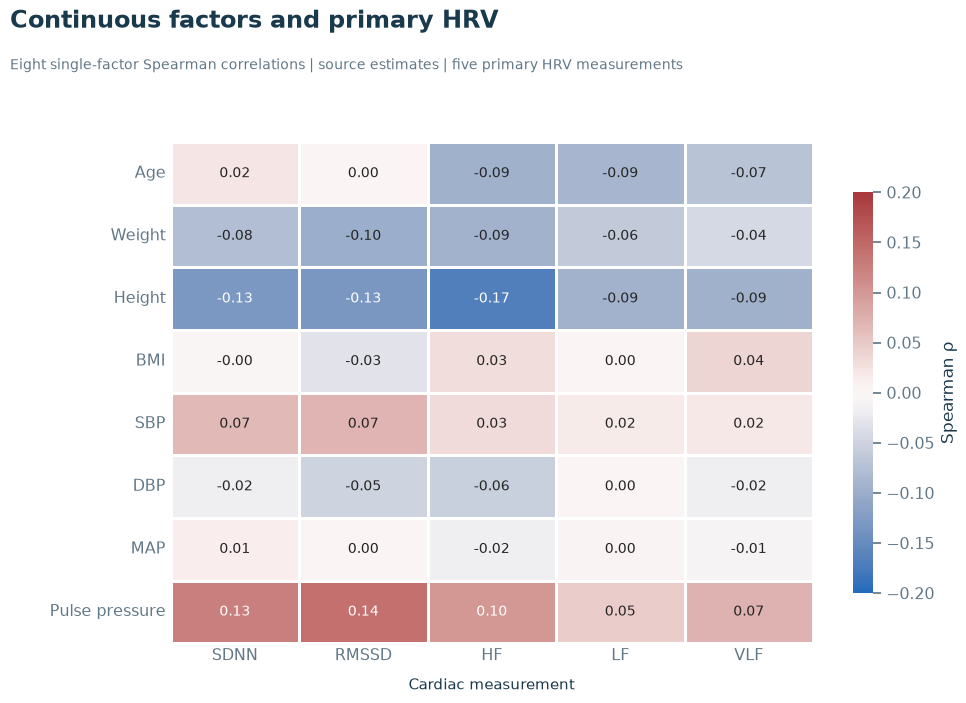

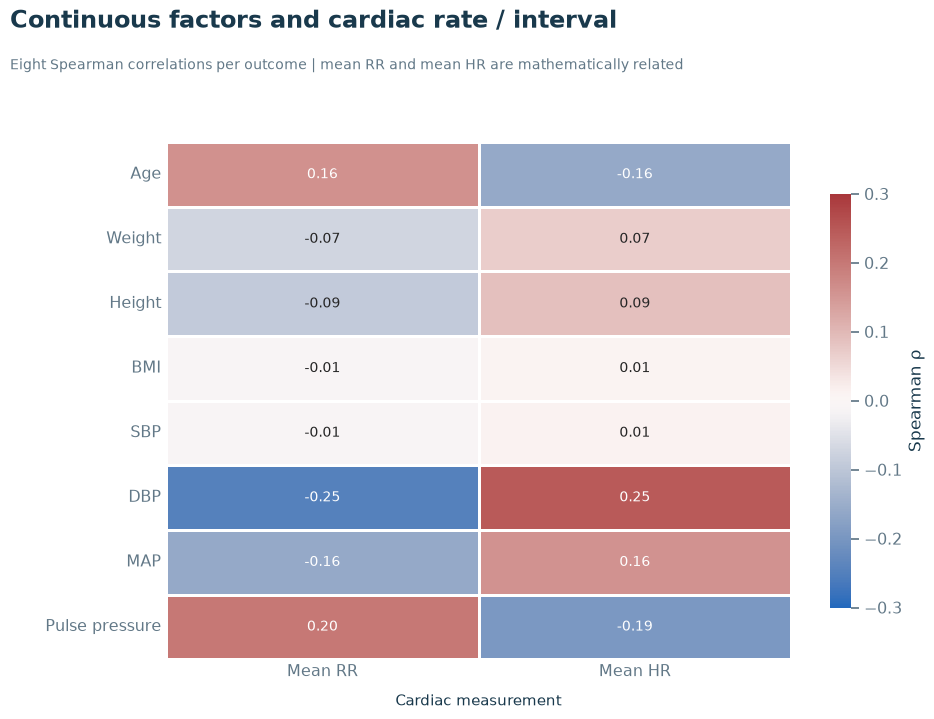

In [6]:
figure_manifest = []


def title_block(fig, title, subtitle):
    height = fig.get_figheight()
    fig.suptitle(title, x=0.064, y=1 - 0.18 / height, ha="left", va="top",
                 fontsize=17.5, fontweight="bold", color=NAVY)
    fig.text(0.064, 1 - 0.67 / height, subtitle, ha="left", va="top",
             fontsize=10, color=MUTED)


def place_axes(fig, left=0.16, right=0.97, top_inches=1.47, bottom_inches=0.75,
               wspace=0.30, hspace=0.4):
    height = fig.get_figheight()
    fig.subplots_adjust(left=left, right=right, top=1 - top_inches / height,
                        bottom=bottom_inches / height, wspace=wspace, hspace=hspace)


def style_plot(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E5ECF1", lw=0.8)
    ax.grid(axis="y", visible=False)
    ax.tick_params(labelsize=9.5)


def save_figure(fig, name, description):
    path = fig_dir / name
    fig.savefig(path, dpi=PLOT_DPI, bbox_inches="tight", pad_inches=0.20)
    figure_manifest.append({"figure": str(path.relative_to(output_root)), "description": description})
    if SHOW_FIGURES:
        plt.show()
    plt.close(fig)


def diverging_limit(values, minimum=0.2):
    valid = np.asarray(values, dtype=float)
    valid = valid[np.isfinite(valid)]
    observed = np.max(np.abs(valid)) if valid.size else minimum
    return min(1.0, max(minimum, np.ceil(observed * 10) / 10))


def heatmap(data_matrix, filename, title, subtitle, signed=True, cmap="vlag", value_format=".2f",
            label="Effect estimate", minimum=0.2, figsize=None):
    rows, cols = data_matrix.shape
    if figsize is None:
        figsize = (max(11, 3.5 + 1.35 * cols), max(5.6, 3.2 + 0.53 * rows))
    fig, ax = plt.subplots(figsize=figsize)
    title_block(fig, title, subtitle)
    place_axes(fig, left=0.21 if rows > 5 else 0.26, right=0.94, top_inches=1.51,
               bottom_inches=0.92)
    values = data_matrix.to_numpy(dtype=float)
    if signed:
        vmax = diverging_limit(values, minimum=minimum)
        opts = dict(vmin=-vmax, vmax=vmax, center=0, cmap=cmap)
    else:
        vmax = max(0.05, np.ceil(np.nanmax(values) * 20) / 20) if np.isfinite(values).any() else 0.05
        opts = dict(vmin=0, vmax=vmax, cmap=cmap)
    sns.heatmap(data_matrix, ax=ax, annot=True, fmt=value_format, linewidths=1,
                linecolor="white", cbar_kws={"label": label, "shrink": 0.8},
                annot_kws={"size": 10.1}, **opts)
    ax.set_xlabel("Cardiac measurement", fontsize=11, labelpad=10, color=NAVY)
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=0, length=0)
    ax.tick_params(axis="y", labelrotation=0, length=0)
    save_figure(fig, filename, subtitle)


# Long-format, numerically comparable Spearman estimates only.
continuous_factor_order = list(CONTINUOUS_META)
binary_factor_order = list(BINARY_META)
multigroup_factor_order = list(MULTIGROUP_META)

def ordered_matrix(frame, col, factors, outcomes):
    return frame.pivot(index="factor", columns="outcome", values=col).reindex(
        index=factors, columns=outcomes).rename(
        index=lambda x: (CONTINUOUS_META.get(x) or BINARY_META.get(x) or MULTIGROUP_META.get(x))[0],
        columns=MEASURES)

heatmap(ordered_matrix(continuous, "spearman_rho", continuous_factor_order, list(PRIMARY)),
        "01_continuous_primary_spearman_heatmap.png", "Continuous factors and primary HRV",
        "Eight single-factor Spearman correlations | source estimates | five primary HRV measurements",
        label="Spearman ρ", minimum=0.2)
heatmap(ordered_matrix(continuous, "spearman_rho", continuous_factor_order, list(COMPLEMENTARY)),
        "02_continuous_complementary_spearman_heatmap.png", "Continuous factors and cardiac rate / interval",
        "Eight Spearman correlations per outcome | mean RR and mean HR are mathematically related",
        label="Spearman ρ", minimum=0.2, figsize=(10.7, 7.6))

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


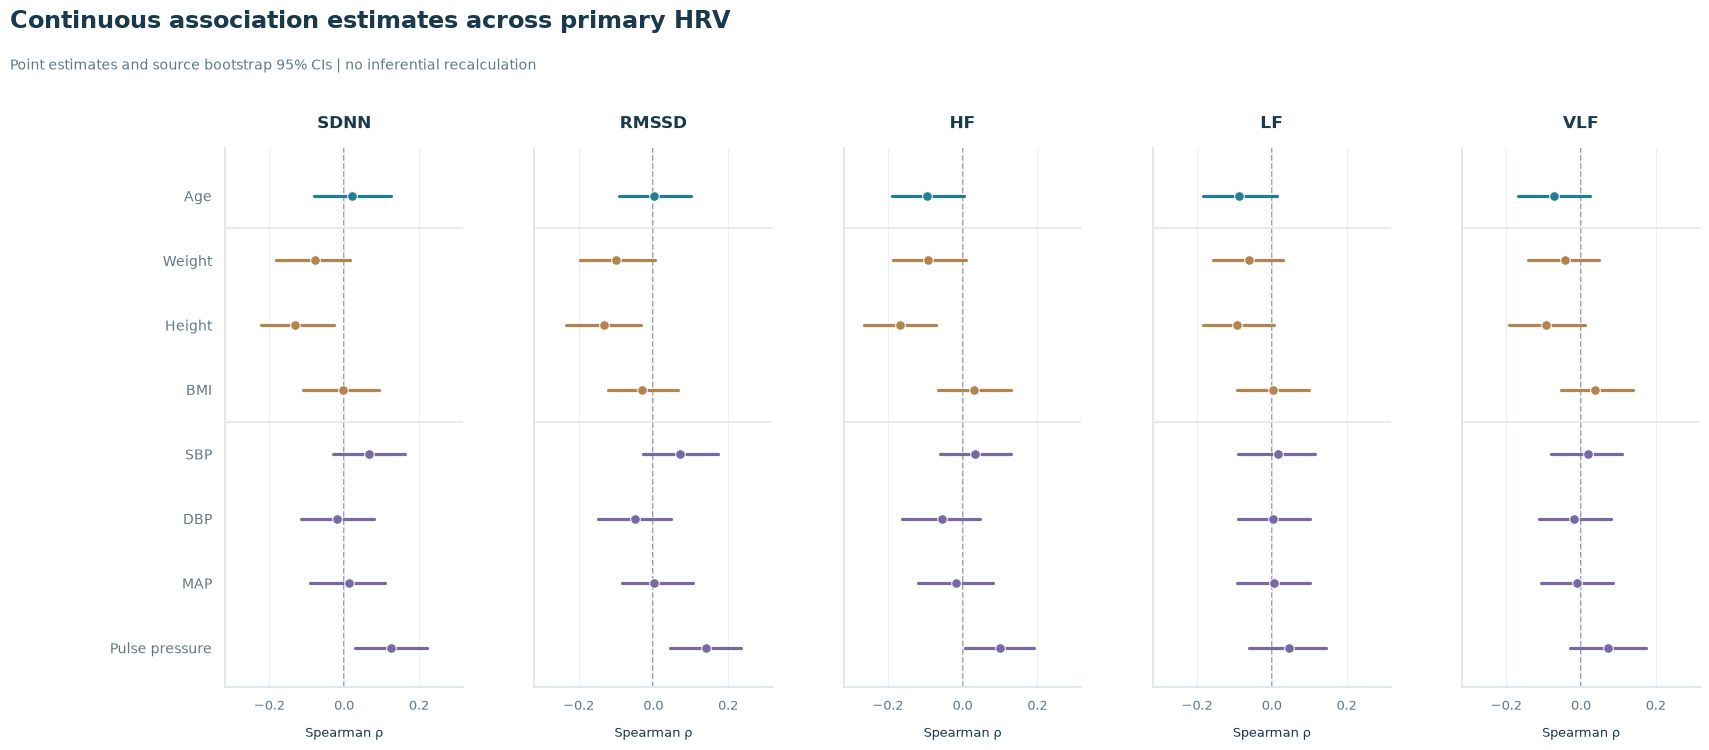

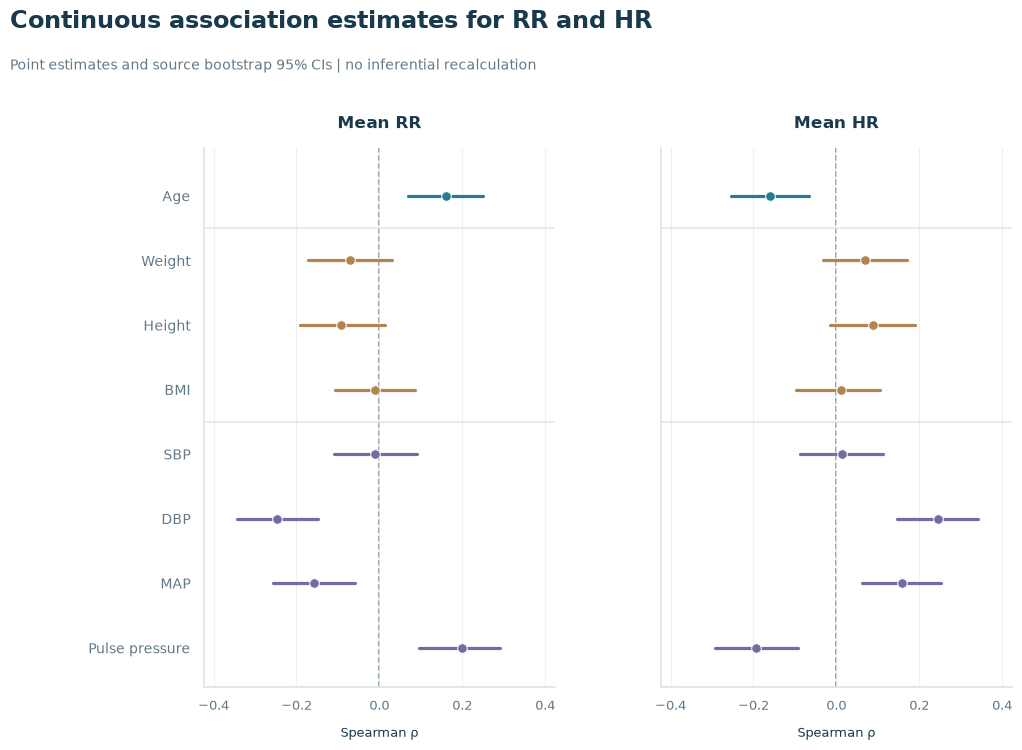

In [7]:
def rho_forest(outcomes, filename, heading):
    factors = list(CONTINUOUS_META)
    ncol = len(outcomes)
    fig, axes = plt.subplots(1, ncol, figsize=(max(11.0, ncol * 3.35 + 1.8), 7.8), sharey=True)
    axes = np.atleast_1d(axes)
    title_block(fig, heading, "Point estimates and source bootstrap 95% CIs | no inferential recalculation")
    place_axes(fig, left=0.18 if ncol > 2 else 0.24, right=0.975, top_inches=1.56,
               bottom_inches=0.85, wspace=0.30)
    selected = continuous.loc[continuous["outcome"].isin(outcomes)]
    lim = diverging_limit(np.r_[selected["rho_ci_low"], selected["rho_ci_high"]], minimum=0.2)
    yp = np.arange(len(factors))[::-1]
    for ax, outcome in zip(axes, outcomes):
        sub = selected.set_index(["factor", "outcome"]).loc[
            [(f, outcome) for f in factors]
        ].reset_index()
        for idx, row in sub.iterrows():
            c = DOMAIN_COLORS[CONTINUOUS_META[row["factor"]][1]]
            ax.plot([row["rho_ci_low"], row["rho_ci_high"]], [yp[idx], yp[idx]], color=c, lw=2.3)
            ax.scatter(row["spearman_rho"], yp[idx], color=c, s=48, zorder=4, edgecolor="white", linewidth=0.7)
        ax.axvline(0, lw=1.1, color="#7A8A96", ls="--", zorder=0)
        ax.axhline(6.5, color="#E0E7EC", lw=1.2)
        ax.axhline(3.5, color="#E0E7EC", lw=1.2)
        ax.set_xlim(-lim * 1.06, lim * 1.06)
        ax.set_ylim(-0.6, len(factors)-0.25)
        ax.set_title(MEASURES[outcome], fontsize=12, color=NAVY, pad=14)
        ax.set_xlabel("Spearman ρ", fontsize=9.5, labelpad=10)
        style_plot(ax)
        ax.set_yticks(yp)
        ax.set_yticklabels([CONTINUOUS_META[f][0] for f in factors], fontsize=10)
    save_figure(fig, filename, "Source Spearman correlations and bootstrap 95% confidence intervals")

rho_forest(list(PRIMARY), "03_continuous_primary_spearman_forest.png",
           "Continuous association estimates across primary HRV")
rho_forest(list(COMPLEMENTARY), "04_continuous_complementary_spearman_forest.png",
           "Continuous association estimates for RR and HR")

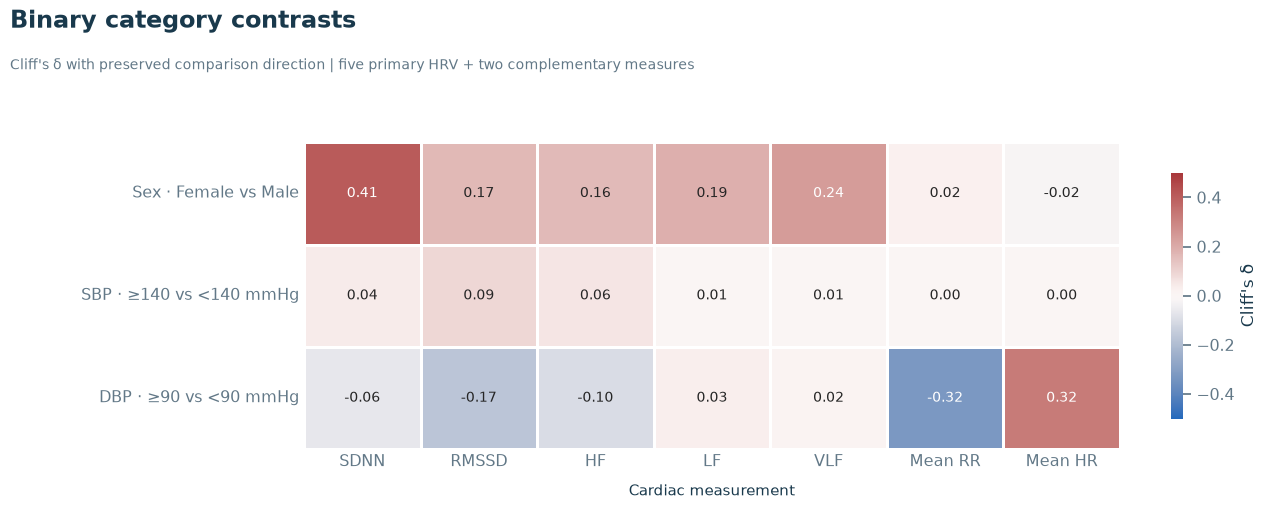

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


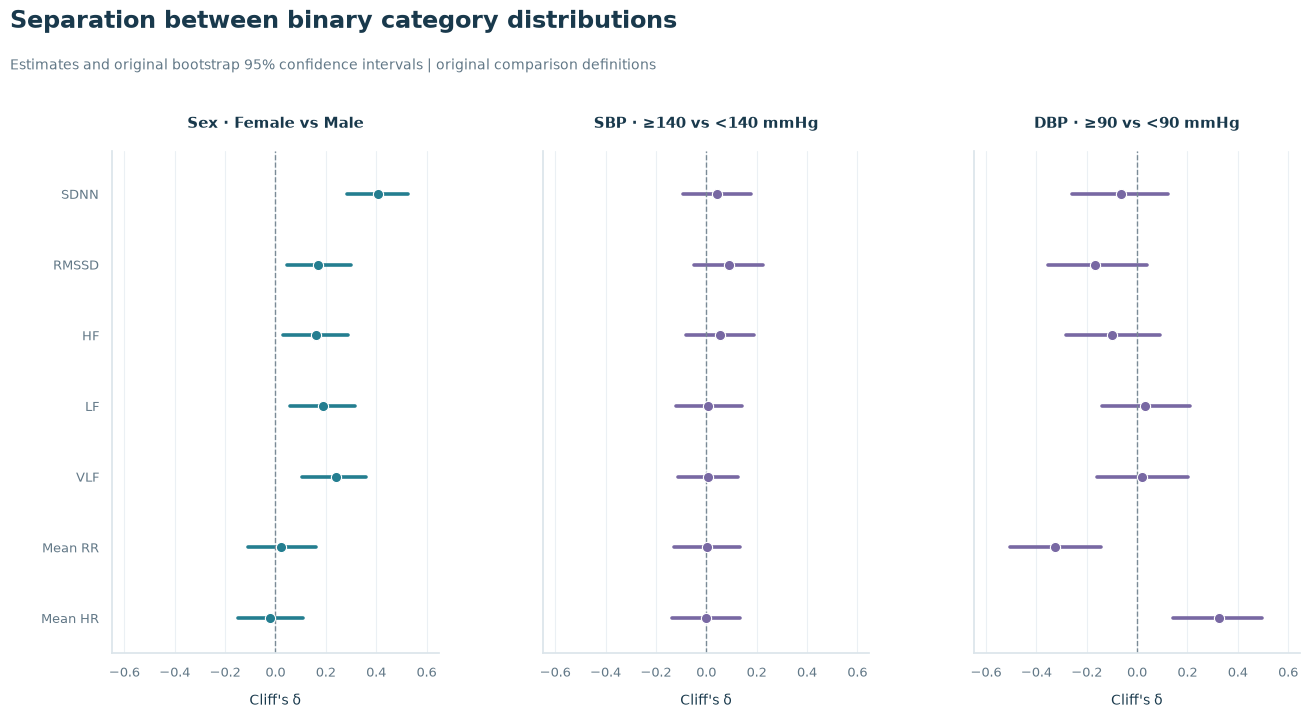

In [8]:
heatmap(ordered_matrix(binary, "cliffs_delta", binary_factor_order, OUTCOME_ORDER),
        "05_binary_cliffs_delta_heatmap.png", "Binary category contrasts",
        "Cliff's δ with preserved comparison direction | five primary HRV + two complementary measures",
        label="Cliff's δ", minimum=0.2, figsize=(15, 5.5))


def group_forest(frame, factors, outcomes, value, low, high, meta, filename,
                 title, xlabel, signed=True):
    fig, axes = plt.subplots(1, len(factors), figsize=(max(12, 4.8*len(factors)), 7.5), sharey=True)
    axes = np.atleast_1d(axes)
    title_block(fig, title, "Estimates and original bootstrap 95% confidence intervals | original comparison definitions")
    place_axes(fig, left=0.135, right=0.96, top_inches=1.6, bottom_inches=0.88, wspace=0.32)
    suball = frame.loc[frame["factor"].isin(factors) & frame["outcome"].isin(outcomes)]
    lowmin = suball[low].min()
    highmax = suball[high].max()
    if signed:
        limit = diverging_limit(np.r_[suball[low], suball[high]], minimum=0.2)
        xmin, xmax = -limit*1.08, limit*1.08
    else:
        xmin = min(0, lowmin)
        xmax = max(0.05, highmax)
        span = xmax-xmin
        xmin -= span * 0.08
        xmax += span * 0.15
    yp = np.arange(len(outcomes))[::-1]
    for ax, factor in zip(axes, factors):
        sub = frame.loc[frame["factor"] == factor].set_index("outcome").loc[outcomes].reset_index()
        col = DOMAIN_COLORS[meta[factor][1]]
        for j, row in sub.iterrows():
            ax.plot([row[low], row[high]], [yp[j], yp[j]], color=col, lw=2.6)
            ax.scatter(row[value], yp[j], s=54, color=col, edgecolors="white", linewidth=0.8, zorder=3)
        ax.axvline(0, color="#7A8A96", ls="--", lw=1.0)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(-0.5, len(outcomes)-0.4)
        ax.set_yticks(yp)
        ax.set_yticklabels([MEASURES[o] for o in outcomes], fontsize=10)
        ax.set_title(meta[factor][0], fontsize=11, pad=17, color=NAVY)
        ax.set_xlabel(xlabel, fontsize=10, labelpad=10)
        style_plot(ax)
    save_figure(fig, filename, "Source effect sizes with bootstrap 95% confidence intervals")


group_forest(binary, binary_factor_order, OUTCOME_ORDER, "cliffs_delta", "cliffs_ci_low", "cliffs_ci_high",
             BINARY_META, "06_binary_cliffs_delta_forest.png", "Separation between binary category distributions",
             "Cliff's δ", signed=True)

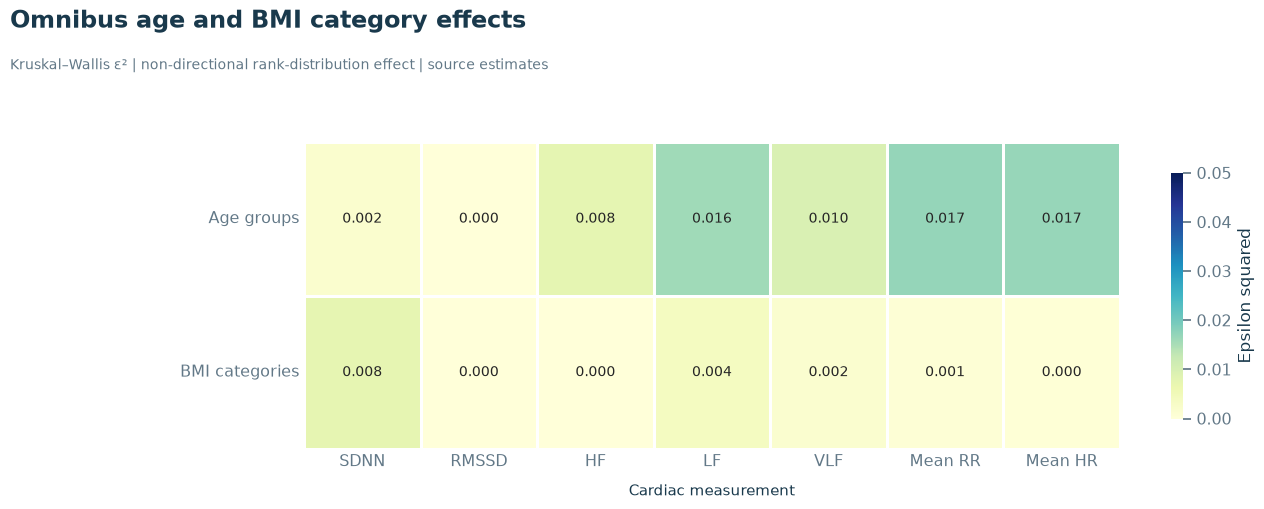

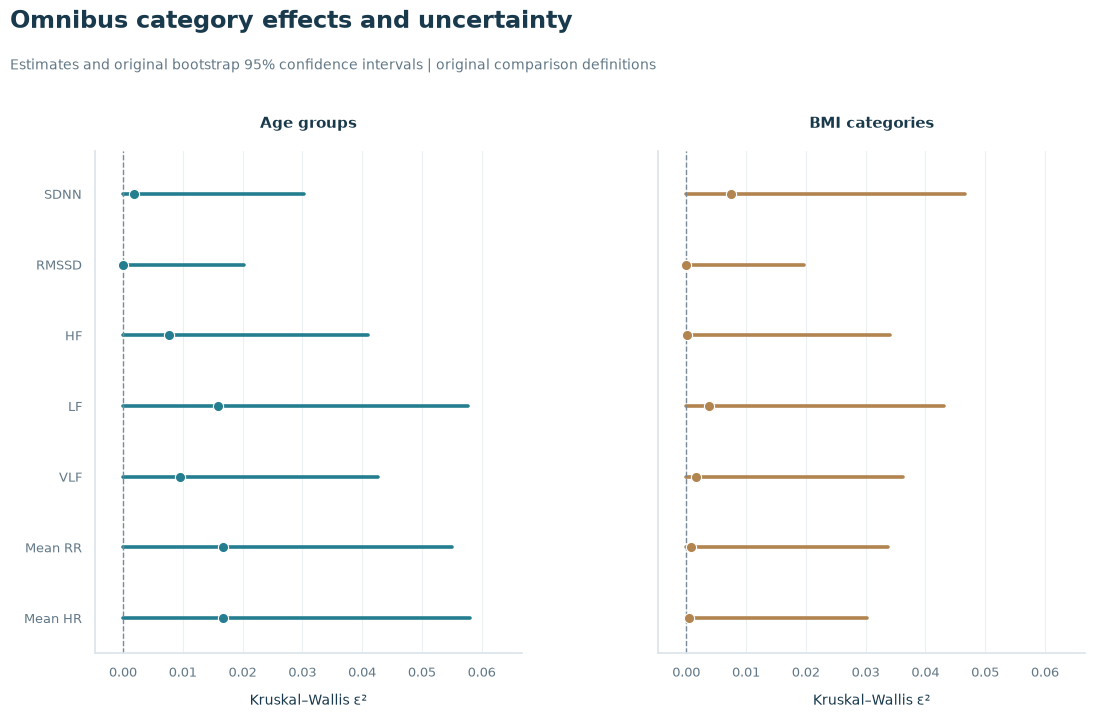

In [9]:
heatmap(ordered_matrix(multigroup, "epsilon_squared", multigroup_factor_order, OUTCOME_ORDER),
        "07_multigroup_epsilon_squared_heatmap.png", "Omnibus age and BMI category effects",
        "Kruskal–Wallis ε² | non-directional rank-distribution effect | source estimates",
        signed=False, cmap="YlGnBu", value_format=".3f", label="Epsilon squared", figsize=(15, 5.5))

group_forest(multigroup, multigroup_factor_order, OUTCOME_ORDER, "epsilon_squared",
             "epsilon_ci_low", "epsilon_ci_high", MULTIGROUP_META,
             "08_multigroup_epsilon_squared_forest.png", "Omnibus category effects and uncertainty",
             "Kruskal–Wallis ε²", signed=False)

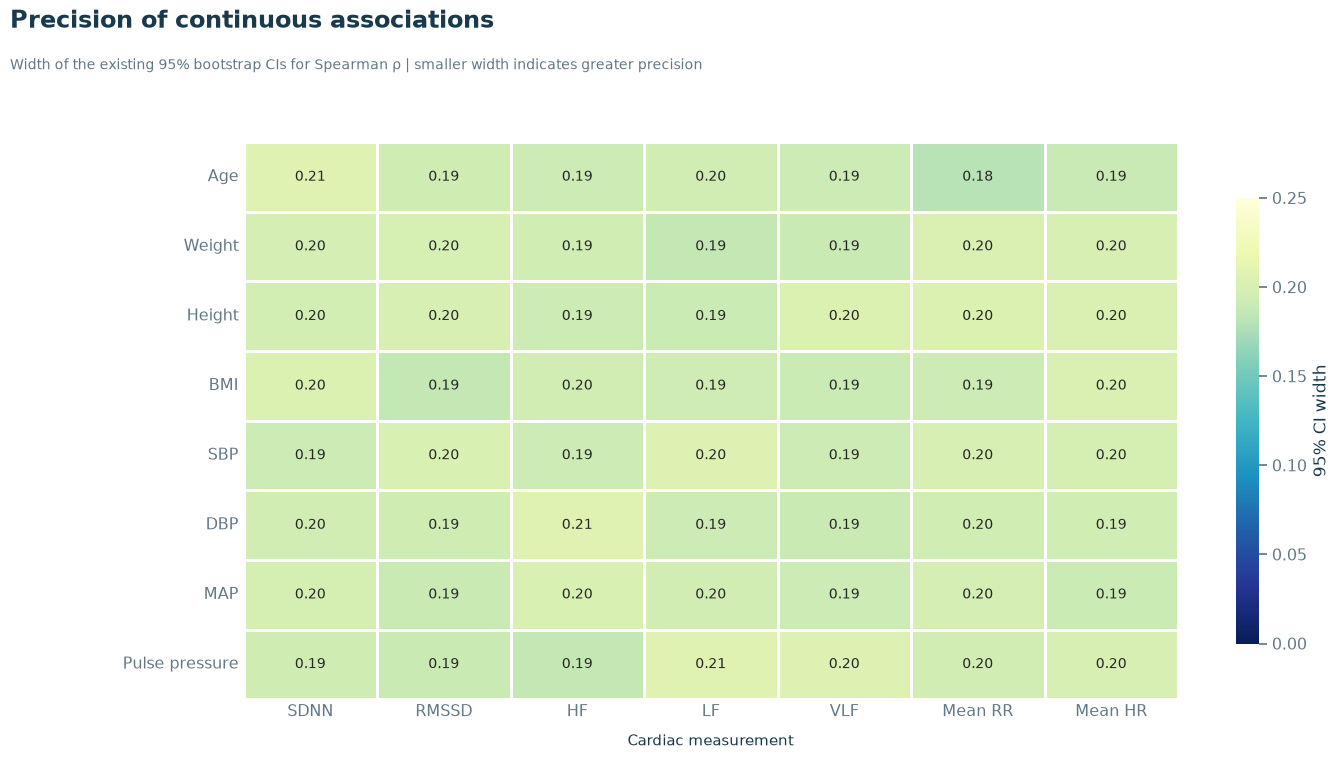

Multipanel synthesis figures generated: 9


In [10]:
# Precision is represented by original confidence-interval width (upper - lower).
# This is a deterministic visualization of already calculated uncertainty, not a new inference step.
ci_widths = continuous.copy()
ci_widths["rho_ci_width"] = ci_widths["rho_ci_high"] - ci_widths["rho_ci_low"]
export_table(ci_widths[["domain", "factor", "factor_label", "outcome", "outcome_label",
                        "rho_ci_low", "rho_ci_high", "rho_ci_width"]], "continuous_ci_widths.csv")
heatmap(ordered_matrix(ci_widths, "rho_ci_width", continuous_factor_order, OUTCOME_ORDER),
        "09_continuous_spearman_precision_heatmap.png", "Precision of continuous associations",
        "Width of the existing 95% bootstrap CIs for Spearman ρ | smaller width indicates greater precision",
        signed=False, cmap="YlGnBu_r", label="95% CI width", figsize=(16, 8.0))

export_table(pd.DataFrame(figure_manifest), "figure_manifest.csv")
print("Multipanel synthesis figures generated:", len(figure_manifest))

## 6. Synthesis documentation and full results report

The report includes **all** estimates, not merely findings that cross a significance threshold. The FDR columns carry the original adjustments from their corresponding domain-specific analysis. The synthesis does not adjust them again or assert that all domains share a single multiplicity family.

Interpretation boundaries: single-factor associations are unadjusted, observational relationships. Age and BMI categories are alternative representations of continuous factors. Weight and BMI share mathematical information; MAP and pulse pressure derive from SBP/DBP. Mean RR and Mean HR are mathematically related. Results from these variables must not be counted as independent physiological evidence.

In [11]:
def format_report_value(value, column, digits=3):
    if pd.isna(value):
        return "—"
    if column in {"p", "Within-domain BH q"} and float(value) < 0.001:
        return "q < 0.001" if column == "Within-domain BH q" else "p < 0.001"
    if isinstance(value, (int, float, np.number)):
        return f"{value:.{digits}f}"
    return str(value)

def markdown_table(frame, numeric_digits=3):
    columns = list(frame.columns)
    out = ["| " + " | ".join(map(str, columns)) + " |",
           "| " + " | ".join(["---"]*len(columns)) + " |"]
    for _, row in frame.iterrows():
        out.append("| " + " | ".join(format_report_value(row[c], c, numeric_digits).replace("|", "/") for c in columns) + " |")
    return "\n".join(out)


readme = f"""# HRV analysis 06.04 — Cross-domain association synthesis

## Scope
This is the fourth and final notebook of the one-factor HRV association phase.
It integrates finalized outputs from `06_01_demographic_associations`,
`06_02_anthropometric_associations` and `06_03_blood_pressure_associations`.
It never reloads the source dataset or fits new statistical models.

## Inputs
Source root: `{analysis_root}`. Read the preceding notebooks' exported CSV tables
under their respective `tables/` directories. Required inputs are the three continuous
Spearman tables, sex and blood-pressure binary contrast tables, two Kruskal–Wallis
omnibus tables, and three descriptive-profile tables. Two exploratory contrast tables
are included when generated by the preceding notebooks.

## Statistical interpretation
- Spearman rho: eight continuous factors × seven cardiac measures (unadjusted associations).
- Cliff's delta: sex (Female vs Male), SBP high vs low, DBP high vs low.
- Kruskal–Wallis epsilon squared: age-group and BMI-category omnibus effects.
- Confidence intervals, raw p-values, within-domain BH-FDR q-values and optional within-outcome
  Holm-adjusted exploratory p-values are **copied unchanged** from source outputs.
- Epsilon squared is non-directional. Do not compare it on the Cliff's delta or Spearman scales.
- **FDR scope:** Benjamini–Hochberg adjustments were carried out separately for each domain and separately for primary HRV and complementary cardiac measures. The demographic, anthropometric and blood-pressure domains contain 15, 20 and 30 primary-HRV tests, respectively (65 across domains), plus 6, 8 and 12 complementary tests (26 across domains). The synthesis retains the original within-domain q-values **without pooled recalculation**. These q-values do not control FDR across all 65 primary-HRV tests or all 26 complementary tests; they must never be described as study-wide adjusted values. Exploratory age- and BMI-group contrasts retain the source Holm adjustments within each outcome.
- A small or non-significant estimate does not establish equivalence or physiological absence.
- Mean RR and Mean HR represent intrinsically linked interval/rate information.
- BMI shares information with weight/height; MAP and PP share information with SBP and DBP.
- All results remain observational and unadjusted. Original bootstrap intervals assume independent source records and do not account for potential correlations between records from the same project. No new exclusions or transformations occur.
- Source category descriptive statistics use original measurement scales.

## Generated tables
- `continuous_associations_combined.csv`
- `binary_cliffs_delta_combined.csv`
- `multigroup_epsilon_squared_combined.csv`
- `categorical_descriptive_profiles_combined.csv`
- `exploratory_contrasts_combined.csv` if upstream exploratory outputs exist
- `all_association_effects_long.csv`
- `continuous_ci_widths.csv`
- `figure_manifest.csv`

## Figures
Nine publication-oriented Seaborn / Matplotlib multipanel figures are saved to
`figures/multipanels/`. The figure manifest contains their names and descriptions.
Figures present existing estimates without recalculation and show primary HRV outcomes
separately from complementary cardiac measures where appropriate.

## Execution
Run after notebooks 06.01–06.03 have generated their output tables.
Set `ANALYSIS_ROOT_OVERRIDE` when running outside the project folder.
All outputs are written to `eda_results/hrv_associations/06_04_association_synthesis/`.
The original outputs of stages 06.01–06.03 are never overwritten.

## Runtime
Python {platform.python_version()}, pandas {pd.__version__}, NumPy {np.__version__},
Matplotlib {matplotlib.__version__}, Seaborn {sns.__version__}.
"""
(output_root / "README_06_04_association_synthesis.md").write_text(readme, encoding="utf-8")


def summary_section(df, metric, lo, hi, title):
    a = df[["domain", "factor_label", "outcome_label", metric, lo, hi,
            "p_raw", "p_fdr_bh"]].copy()
    a.columns = ["Domain", "Factor", "Outcome", "Effect", "95% CI lower", "95% CI upper", "p", "Within-domain BH q"]
    return "\n## " + title + "\n\n" + markdown_table(a, 3) + "\n"

report = f"""# 06.04 — Cross-domain synthesis of individual HRV associations

**Scope:** synthesis of three preceding unifactorial stages; no additional hypothesis tests.

## Output inventory
- Eight continuous factors and seven cardiac measures: **{len(continuous)}** original Spearman estimates.
- Three binary factors and seven cardiac measures: **{len(binary)}** original Cliff's delta estimates.
- Two multi-group factors and seven cardiac measures: **{len(multigroup)}** original omnibus epsilon-squared estimates.
- Original descriptive category profiles: **{len(profiles)}** rows (one overall reference row).
- Available optional exploratory pairwise contrasts: **{len(exploratory)}**.
- Figures: **{len(figure_manifest)}** consolidated sheets.

## Interpretation
The tables below show all recorded effect sizes, uncertainty intervals, raw p-values and
preexisting BH-FDR results, including associations without statistical significance.
FDR was adjusted separately within each of the three source domains, and primary and complementary outcomes form separate families. The original q-values are **not pooled across domains** (65 primary-HRV tests and 26 complementary tests altogether); no study-wide FDR claim is made. Spearman rho, Cliff's delta and epsilon squared represent
different estimands and are not directly interchangeable. No causal inference or
multivariable adjustment is undertaken here.
"""
report += summary_section(continuous, "spearman_rho", "rho_ci_low", "rho_ci_high", "Continuous factor associations — Spearman rho")
report += summary_section(binary, "cliffs_delta", "cliffs_ci_low", "cliffs_ci_high", "Binary category comparisons — Cliff's delta")
report += summary_section(multigroup, "epsilon_squared", "epsilon_ci_low", "epsilon_ci_high", "Age and BMI category omnibus comparisons — epsilon squared")
report += "\n## Complete descriptive and exploratory tables\n\n"
report += "All source-scale category profiles are retained in `tables/categorical_descriptive_profiles_combined.csv`.\n"
if not exploratory.empty:
    report += "All available age- and BMI-category exploratory comparisons, including source Holm corrections, are retained in `tables/exploratory_contrasts_combined.csv`.\n"
report += "\n## Figure index\n\n" + markdown_table(pd.DataFrame(figure_manifest)) + "\n"
report += "\n## Interpretation limitations\n\n"
report += ("The estimates describe unadjusted, cross-sectional relationships among the recorded observations. "
           "Category overlap, source projects and physiological/algebraic relationships must be considered when writing the article. "
           "A non-significant association is not evidence that an effect is absent. The uncertainty interval and the magnitude matter. Original bootstrap intervals assume independent records and do not account for potential within-project correlation. Exact numeric p and q values are stored in the CSV files; values below 0.001 are rendered as inequalities in this report.\n")
(output_root / "06_04_association_synthesis_results.md").write_text(report, encoding="utf-8")

print("Written README and complete results report")
print("Tables:", len(list(tables_dir.glob("*.csv"))), "| Figures:", len(list(fig_dir.glob("*.png"))))
print("Completed 06.04 — final unifactorial synthesis notebook")

Written README and complete results report
Tables: 8 | Figures: 9
Completed 06.04 — final unifactorial synthesis notebook


## 7. What this closes — and what it does not

With the previous stages available, this notebook closes the **descriptive and inferential one-factor association phase**. Any subsequent age × sex, sex × BMI, BMI × BP, adjusted, or longitudinal analysis constitutes a **separate research decision and phase**, not an automatic extension of 06.04.

For manuscript drafting, interpret the observed effect **magnitudes and uncertainty** first. Do not infer the absence of an association from a non-significant test, and do not claim independent confirmation from algebraically linked measurements.